In [19]:
import polars as pl
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

In [11]:
df = pl.read_excel("profile_coeffs_ref.xlsx")

In [12]:
filtered_df = df.filter(
    ~(
        pl.col("Source").str.contains("Acid") | 
        pl.col("Source").str.contains("FAME") | 
        pl.col("Source").str.contains("MAG/DAG")
    )
)

In [15]:
mean_values = filtered_df.group_by('Source').agg(
    pl.col('m').mean().alias('m_mean'),
    pl.col('n').mean().alias('n_mean'),
    pl.col('p').mean().alias('p_mean'),
    pl.col('b').mean().alias('b_mean')
)

print("Mean values per group:")
print(mean_values)

# Now let's create distribution plots for each column across groups
# Assuming you have a reasonable number of groups

# Convert to pandas for easier plotting with seaborn


Mean values per group:
shape: (40, 5)
┌────────────┬───────────┬──────────┬──────────┬──────────┐
│ Source     ┆ m_mean    ┆ n_mean   ┆ p_mean   ┆ b_mean   │
│ ---        ┆ ---       ┆ ---      ┆ ---      ┆ ---      │
│ str        ┆ f64       ┆ f64      ┆ f64      ┆ f64      │
╞════════════╪═══════════╪══════════╪══════════╪══════════╡
│ Garlic     ┆ 13.077415 ┆ 1.326261 ┆ 0.0      ┆ 1.0      │
│ Triolein   ┆ 14.0      ┆ 1.0      ┆ 0.0      ┆ 1.0      │
│ Palm       ┆ 13.882211 ┆ 0.573585 ┆ 0.0      ┆ 1.0      │
│ Canola     ┆ 13.328395 ┆ 1.284957 ┆ 0.0      ┆ 0.0      │
│ Rice Bran  ┆ 13.28067  ┆ 1.149375 ┆ 0.0      ┆ 1.0      │
│ …          ┆ …         ┆ …        ┆ …        ┆ …        │
│ Palm       ┆ 13.851386 ┆ 0.587797 ┆ 0.0      ┆ 1.0      │
│ Brazil Nut ┆ 13.478253 ┆ 1.089109 ┆ 0.0      ┆ 0.5      │
│ Sesame     ┆ 12.864757 ┆ 1.453942 ┆ 0.0      ┆ 1.0      │
│ Waste Fish ┆ 13.361052 ┆ 1.085239 ┆ 0.054183 ┆ 0.0      │
│ Sunflower  ┆ 12.844782 ┆ 1.495299 ┆ 0.0      ┆ 0.428571 │
└─

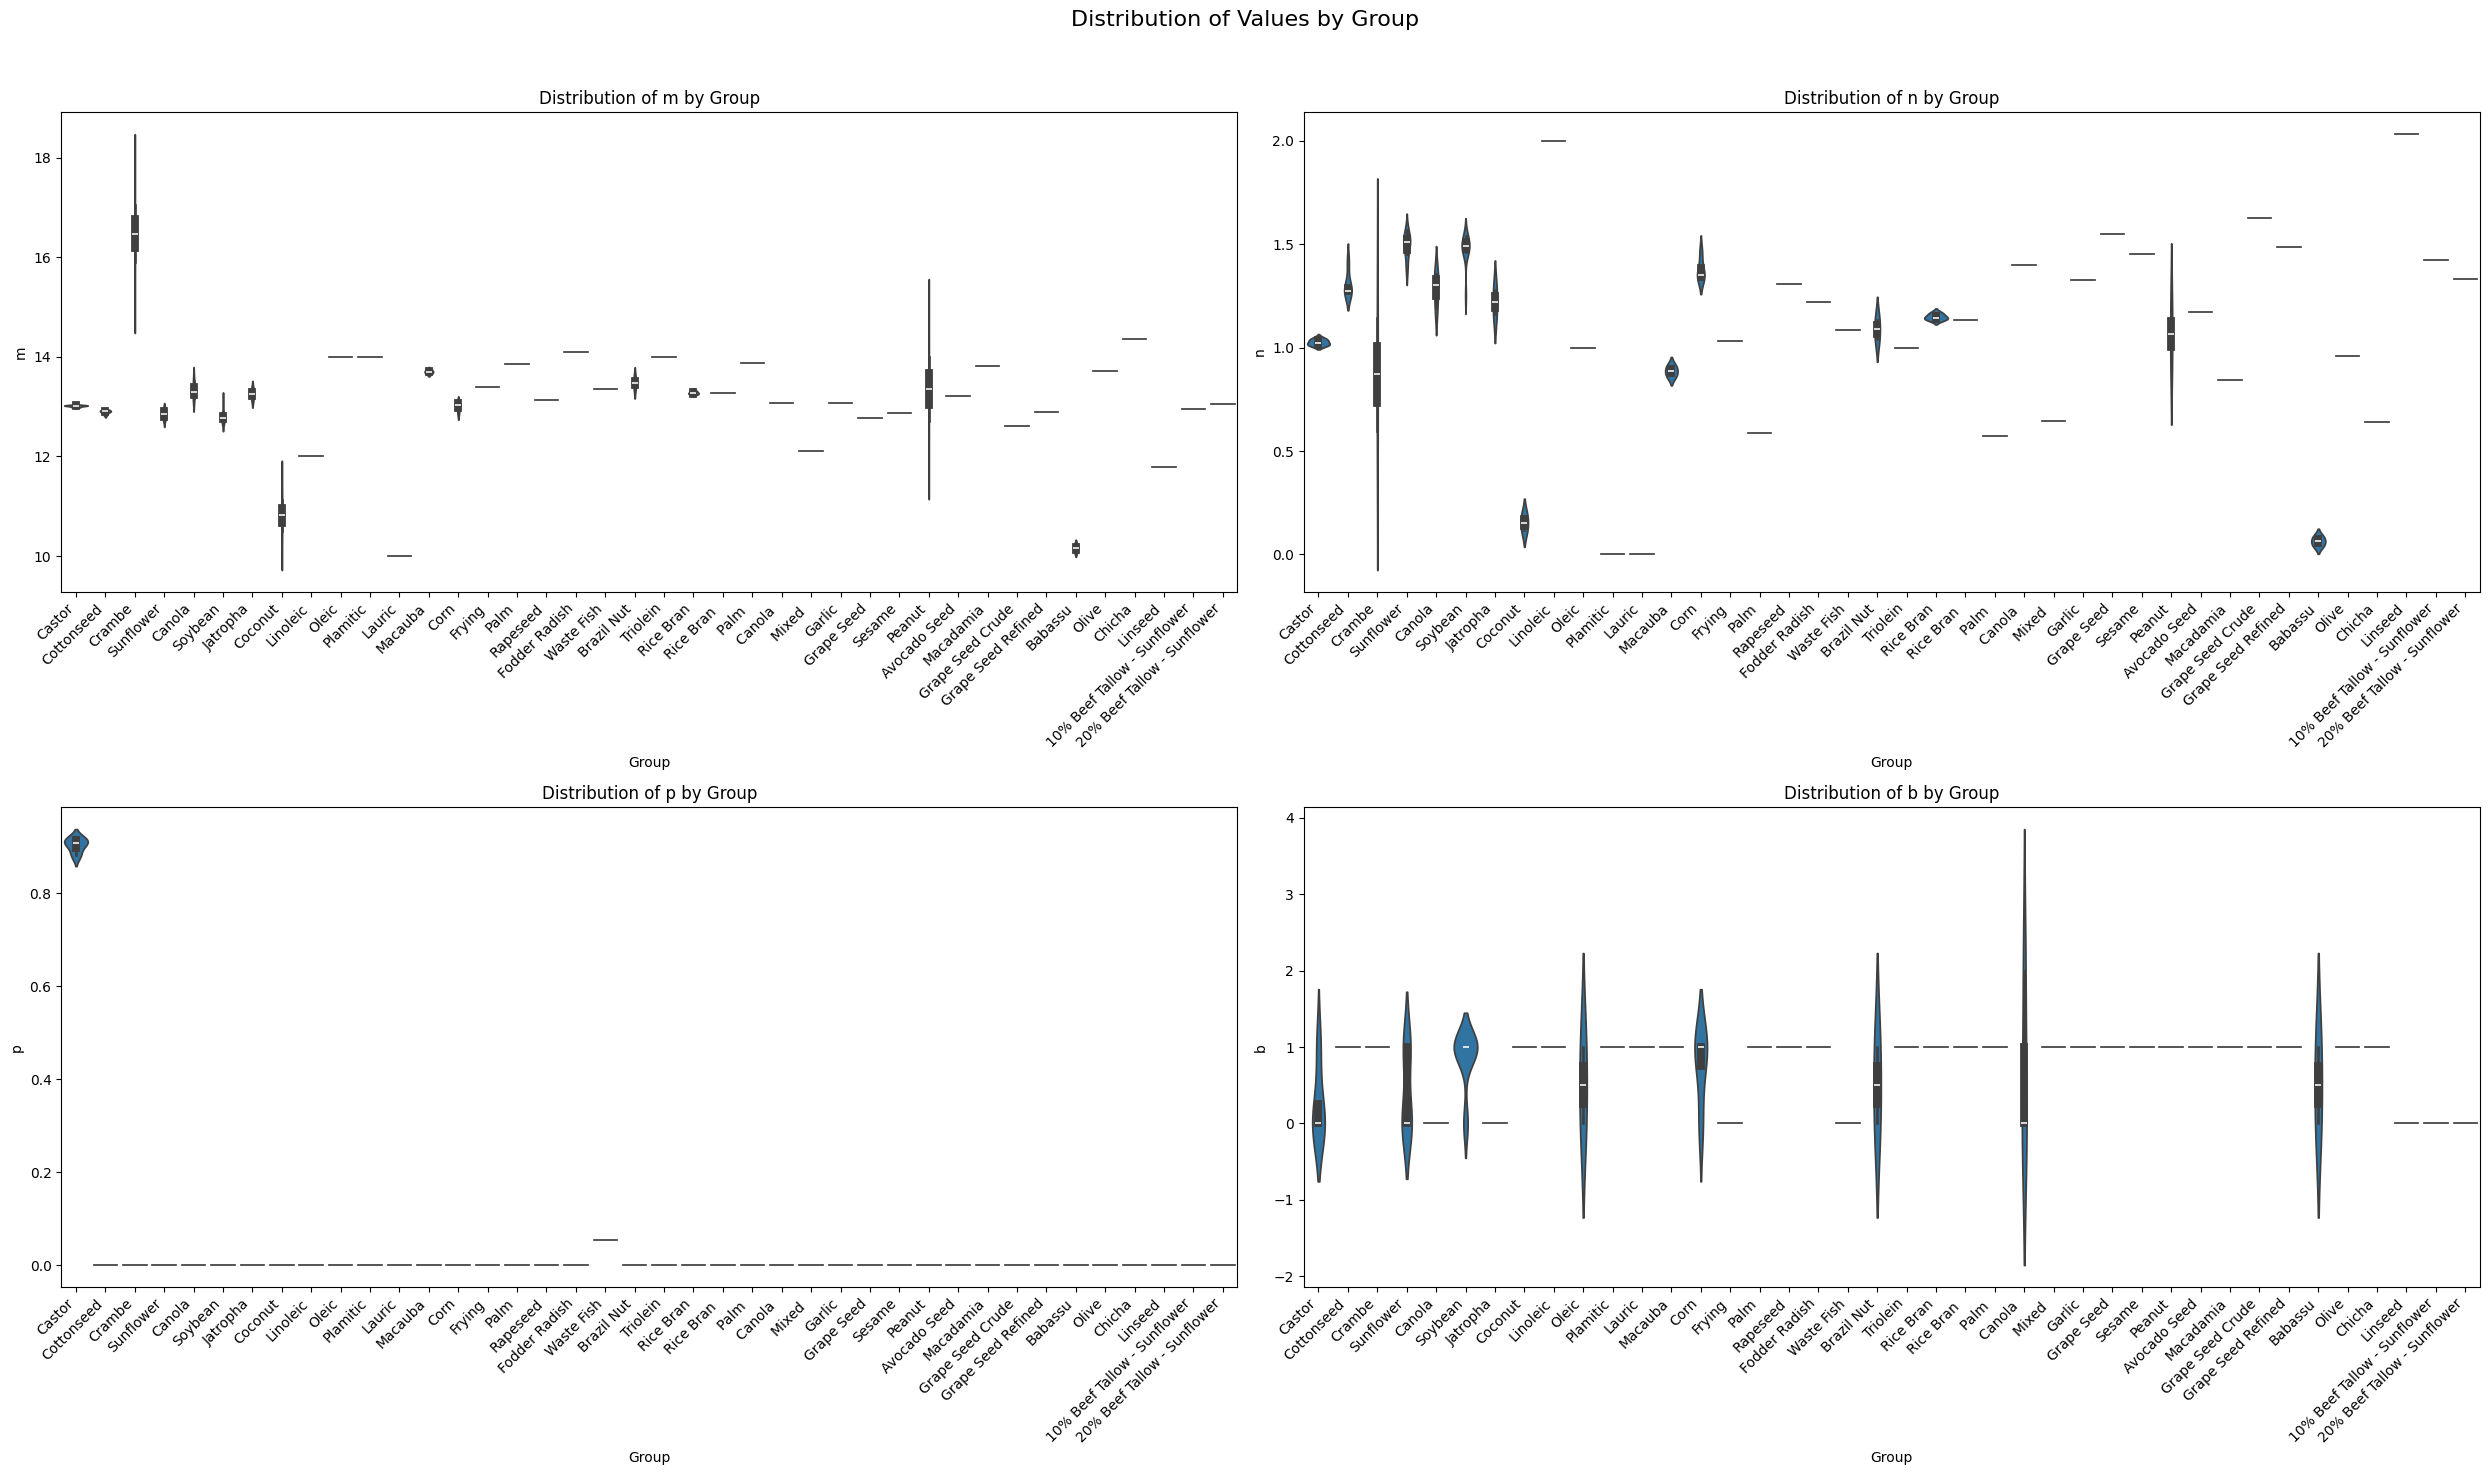

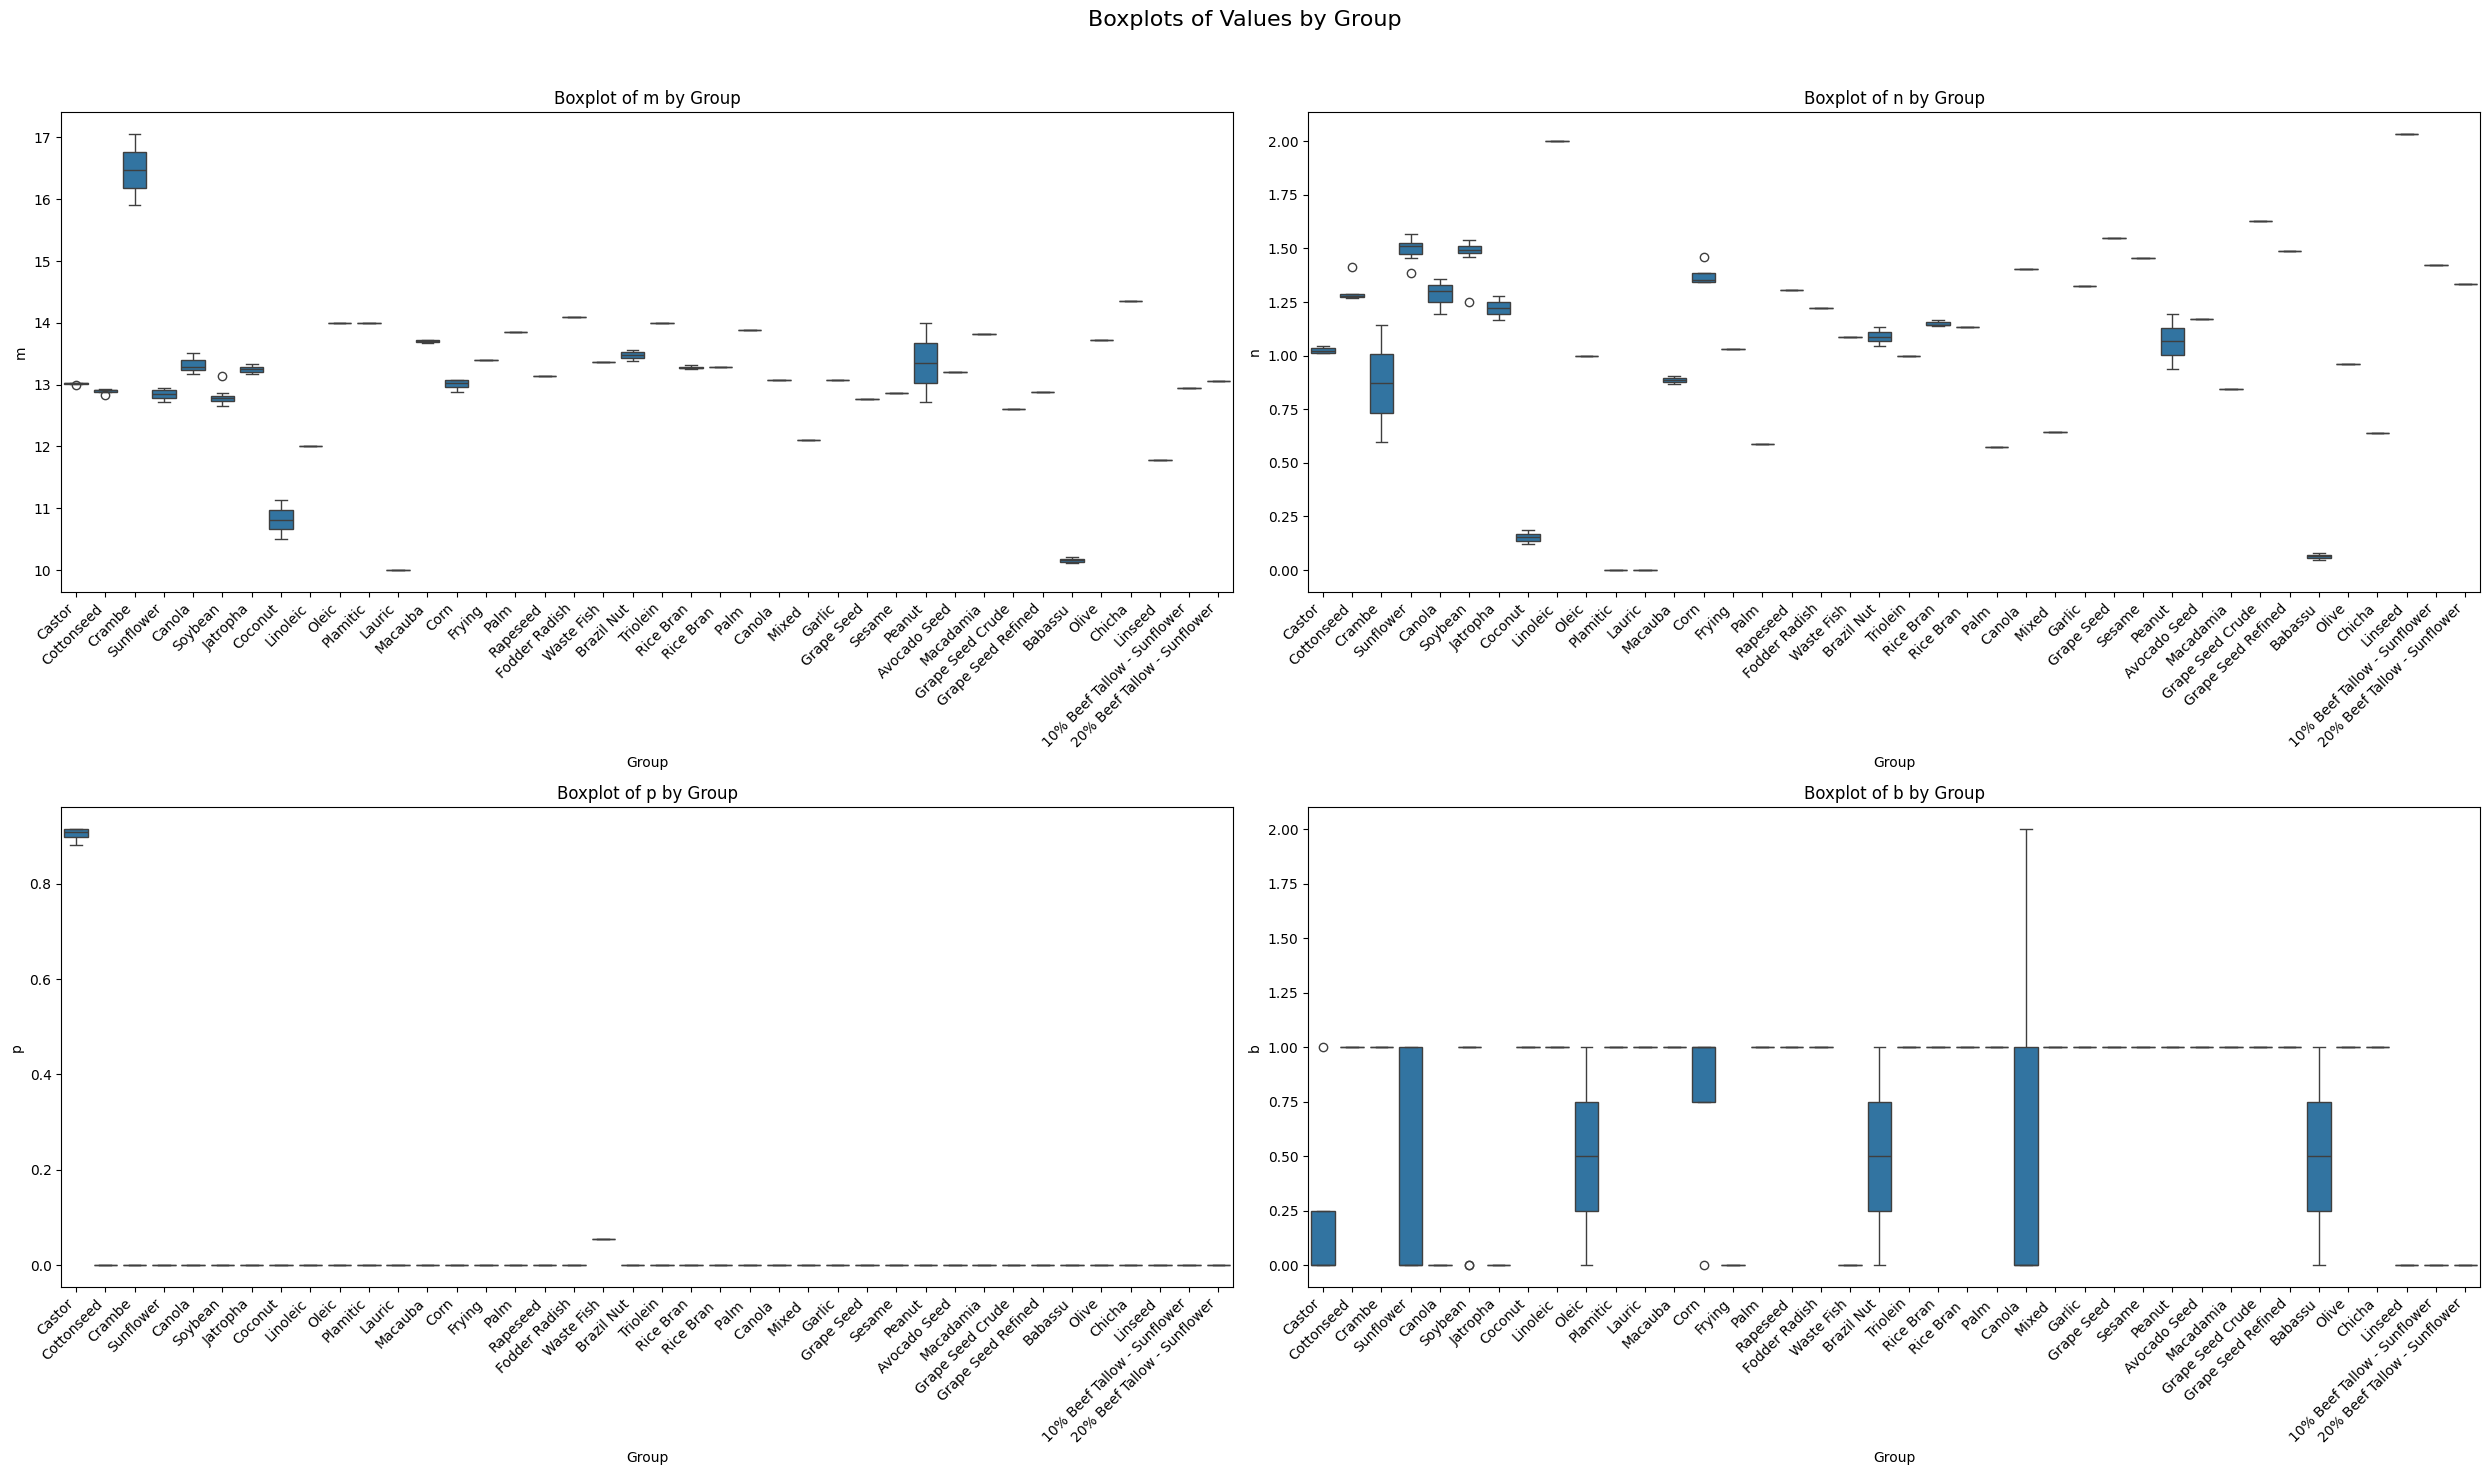

In [25]:
df_pandas = filtered_df.to_pandas()

# Set up the figure
fig, axes = plt.subplots(2, 2, figsize=(25, 15))
fig.suptitle('Distribution of Values by Group', fontsize=16)

# Flatten the axes array for easier iteration
axes = axes.flatten()

# Columns to plot
columns = ['m', 'n', 'p', 'b']

# Create distribution plots
for i, col in enumerate(columns):
    # Using seaborn's violinplot for distribution visualization
    sns.violinplot(x='Source', y=col, data=df_pandas, ax=axes[i])
    axes[i].set_title(f'Distribution of {col} by Group')
    axes[i].set_xlabel('Group')
    axes[i].set_ylabel(col)
    
    # Rotate x-axis labels if there are many groups
    plt.setp(axes[i].get_xticklabels(), rotation=45, ha='right')

# Adjust layout
plt.tight_layout(rect=[0, 0, 1, 0.96])  # Make room for the title
plt.show()

# Alternatively, you can create boxplots which might be clearer
# for comparing distributions between groups
fig, axes = plt.subplots(2, 2, figsize=(25, 15))
fig.suptitle('Boxplots of Values by Group', fontsize=16)

axes = axes.flatten()

for i, col in enumerate(columns):
    sns.boxplot(x='Source', y=col, data=df_pandas, ax=axes[i])
    axes[i].set_title(f'Boxplot of {col} by Group')
    axes[i].set_xlabel('Group')
    axes[i].set_ylabel(col)
    
    # Rotate x-axis labels if there are many groups
    plt.setp(axes[i].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()